<a href="https://colab.research.google.com/github/costpetrides/Numerical-Methods-GFD/blob/main/Petrides/Solutions/Diffusion/FTCS_2D_p.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# <span style="color:rgb(213,80,0)">Μέθοδος FTCS 2D</span>

## Άσκηση 1.

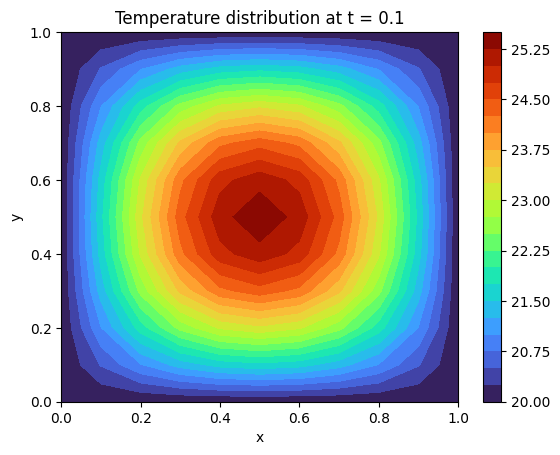

In [1]:
import numpy as np
import matplotlib.pyplot as plt

L = 1
T = 0.1
h = 0.1
k = 0.002
x = np.arange(0,L+h/2,h)[:,None]
y = np.arange(0,L+h/2,h)[None,:]
t = np.arange(0,T+k/2,k)
Nx = x.size
Ny = y.size
Nt = t.size
r = k/h**2
assert r <= 1/4, 'FTCS is unstable'
u = np.zeros((Nx,Ny,Nt))
# Initial condition
u[:,:,0] = 20 + 40*np.sin(np.pi*x)*np.sin(np.pi*y)
# Dirichlet boundary conditions
u[0,:,:]   = 20
u[-1,:,:] = 20
u[:,0,:]   = 20
u[:,-1,:] = 20
# FTCS method
i = np.arange(1,Nx-1)[:,None]
m = np.arange(1,Ny-1)[None,:]
for j in range(Nt-1):
    u[i,m,j+1] = (u[i,m,j] + r*(
        u[i-1,m,j] - 2*u[i,m,j] + u[i+1,m,j])
        + r*(
        u[i,m-1,j] - 2*u[i,m,j] + u[i,m+1,j]))

plt.figure(facecolor='white')
plt.contourf(x[:,0],y[0,:],u[:,:,-1].T,25,cmap='turbo')
plt.colorbar()
plt.axis('equal')
plt.axis('tight')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Temperature distribution at t = 0.1')
plt.show()

## Άσκηση 2.

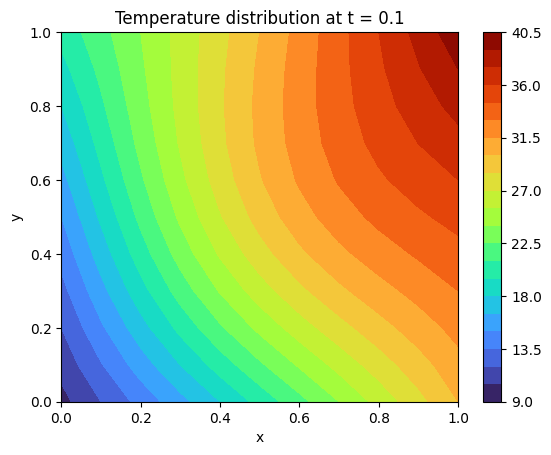

In [2]:
import numpy as np
import matplotlib.pyplot as plt

L = 1
T = 0.1
h = 0.1
k = 0.002
x = np.arange(0,L+h/2,h)[:,None]
y = np.arange(0,L+h/2,h)[None,:]
t = np.arange(0,T+k/2,k)
Nx = x.size
Ny = y.size
Nt = t.size
r = k/h**2
assert r <= 1/4, 'FTCS is unstable'
u = np.zeros((Nx,Ny,Nt))
# Initial condition
u[:,:,0] = ((10 + 20*x + 10*y
    + 30*np.sin(np.pi*x)*np.sin(np.pi*y)))
# FTCS method
i = np.arange(1,Nx-1)[:,None]
m = np.arange(1,Ny-1)[None,:]
for j in range(Nt-1):
    u[i,m,j+1] = (u[i,m,j] + r*(
        u[i-1,m,j] - 2*u[i,m,j] + u[i+1,m,j])
        + r*(
        u[i,m-1,j] - 2*u[i,m,j] + u[i,m+1,j]))
    # Dirichlet boundary conditions
    u[0,:,j+1]   = 10 + 10*y[0,:]
    u[-1,:,j+1] = 30 + 10*y[0,:]
    u[:,0,j+1]   = 10 + 20*x[:,0]
    u[:,-1,j+1] = 20 + 20*x[:,0]

plt.figure(facecolor='white')
plt.contourf(x[:,0],y[0,:],u[:,:,-1].T,25,cmap='turbo')
plt.colorbar()
plt.axis('equal')
plt.axis('tight')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Temperature distribution at t = 0.1')
plt.show()

## Άσκηση 3.

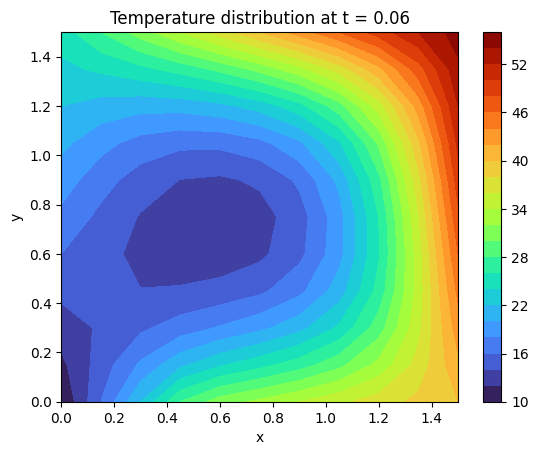

In [3]:
import numpy as np
import matplotlib.pyplot as plt

L = 1.5
T = 0.06
h = 0.15
k = 0.003
x = np.arange(0,L+h/2,h)[:,None]
y = np.arange(0,L+h/2,h)[None,:]
t = np.arange(0,T+k/2,k)
Nx = x.size
Ny = y.size
Nt = t.size
r = k/h**2
assert r <= 1/4, 'FTCS is unstable'
u = np.zeros((Nx,Ny,Nt))
# Initial condition
u[:,:,0] = 10
# Dirichlet boundary conditions

a = x <= 0.5
b = x > 0.5
u[0,:,:]   = 10 + 10*y.T
u[-1,:,:] = 40 + 10*y.T
u[a[:,0],0,:]   = 10 + 20*x[a[:,0]] + 20*x[a[:,0]]
u[b[:,0],0,:]   = 10 + 20*x[b[:,0]] + 10*(1.5-x[b[:,0]])
u[:,-1,:] = 25 + 20*x
# FTCS method
i = np.arange(1,Nx-1)[:,None]
m = np.arange(1,Ny-1)[None,:]
for j in range(Nt-1):
    u[i,m,j+1] = (u[i,m,j] + r*(
        u[i-1,m,j] - 2*u[i,m,j] + u[i+1,m,j])
        + r*(
        u[i,m-1,j] - 2*u[i,m,j] + u[i,m+1,j]))

# Temperature distribution at t = T
plt.figure(facecolor='white')
plt.contourf(x[:,0],y[0,:],u[:,:,-1].T,25,cmap='turbo')
plt.colorbar()
plt.axis('equal')
plt.axis('tight')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Temperature distribution at t = 0.06')
plt.show()

## Άσκηση 4.

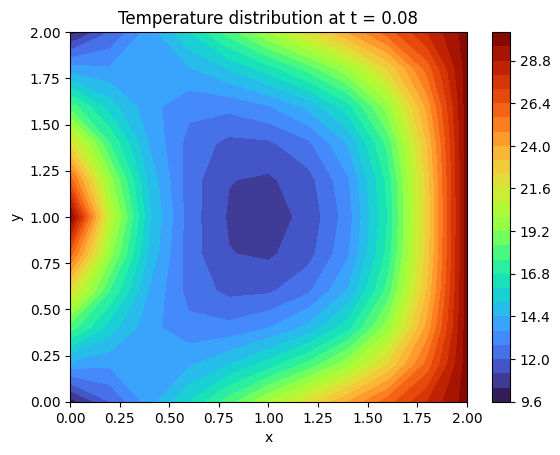

In [4]:
import numpy as np
import matplotlib.pyplot as plt

L = 2
T = 0.08
h = 0.2
k = 0.004
x = np.arange(0,L+h/2,h)[:,None]
y = np.arange(0,L+h/2,h)[None,:]
t = np.arange(0,T+k/2,k)
Nx = x.size
Ny = y.size
Nt = t.size
r = k/h**2
assert r <= 1/4, 'FTCS is unstable'
u = np.zeros((Nx,Ny,Nt))
# Initial condition
u[:,:,0] = 10
# Dirichlet boundary conditions

a = y <= 1
b = y > 1
u[0,a[0,:],:]   = 10 + 20*y[0,a[0,:]][:,None]
u[0,b[0,:],:]   = 10 + 20*(2-y[0,b[0,:]][:,None])
u[-1,:,:] = 30
u[:,0,:]   = 10 + 10*x
u[:,-1,:] = 10 + 10*x
# FTCS method
i = np.arange(1,Nx-1)[:,None]
m = np.arange(1,Ny-1)[None,:]
for j in range(Nt-1):
    u[i,m,j+1] = (u[i,m,j] + r*(
        u[i-1,m,j] - 2*u[i,m,j] + u[i+1,m,j])
        + r*(
        u[i,m-1,j] - 2*u[i,m,j] + u[i,m+1,j]))

# Temperature distribution at t = T
plt.figure(facecolor='white')
plt.contourf(x[:,0],y[0,:],u[:,:,-1].T,25,cmap='turbo')
plt.colorbar()
plt.axis('equal')
plt.axis('tight')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Temperature distribution at t = 0.08')
plt.show()

## Άσκηση 5.

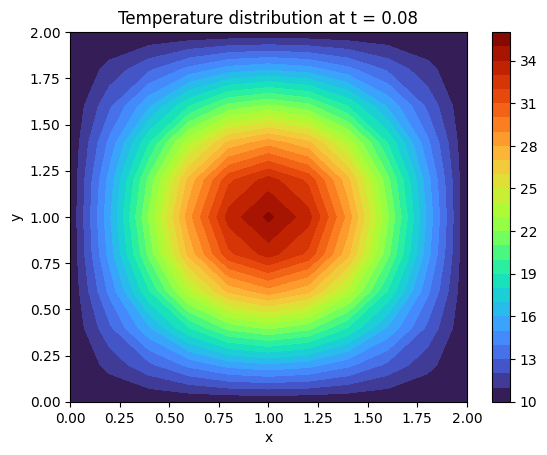

In [5]:
import numpy as np
import matplotlib.pyplot as plt

L = 2
T = 0.08
h = 0.2
k = 0.004
x = np.arange(0,L+h/2,h)[:,None]
y = np.arange(0,L+h/2,h)[None,:]
t = np.arange(0,T+k/2,k)
Nx = x.size
Ny = y.size
Nt = t.size
r = k/h**2
assert r <= 1/4, 'FTCS is unstable'
u = np.zeros((Nx,Ny,Nt))
# Initial condition
a = (x >= 0.5) & (x <= 1.5)
b = (y >= 0.5) & (y <= 1.5)
u[:,:,0] = 10
u[np.ix_(a[:,0],b[0,:],[0])] = 50
# Dirichlet boundary conditions
u[0,:,:]   = 10
u[-1,:,:] = 10
u[:,0,:]   = 10
u[:,-1,:] = 10
# FTCS method
i = np.arange(1,Nx-1)[:,None]
m = np.arange(1,Ny-1)[None,:]
for j in range(Nt-1):
    u[i,m,j+1] = (u[i,m,j] + r*(
        u[i-1,m,j] - 2*u[i,m,j] + u[i+1,m,j])
        + r*(
        u[i,m-1,j] - 2*u[i,m,j] + u[i,m+1,j]))

# Temperature distribution at t = T
plt.figure(facecolor='white')
plt.contourf(x[:,0],y[0,:],u[:,:,-1].T,25,cmap='turbo')
plt.colorbar()
plt.axis('equal')
plt.axis('tight')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Temperature distribution at t = 0.08')
plt.show()

## Άσκηση 6.

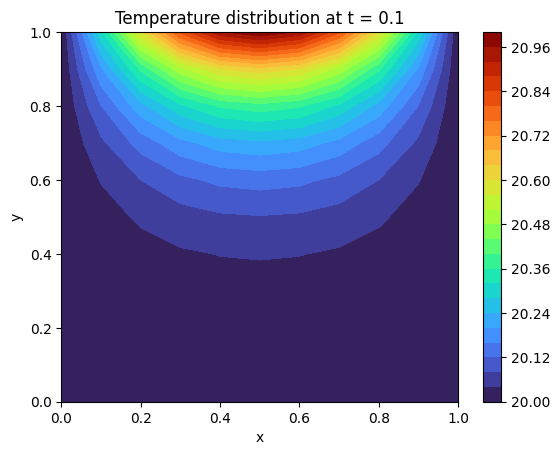

In [6]:
import numpy as np
import matplotlib.pyplot as plt

L = 1
T = 0.1
h = 0.1
k = 0.002
x = np.arange(0,L+h/2,h)[:,None]
y = np.arange(0,L+h/2,h)[None,:]
t = np.arange(0,T+k/2,k)
Nx = x.size
Ny = y.size
Nt = t.size
r = k/h**2
assert r <= 1/4, 'FTCS is unstable'
u = np.zeros((Nx,Ny,Nt))
# Initial condition
u[:,:,0] = 20
# Dirichlet boundary conditions
u[0,:,:]   = 20
u[-1,:,:] = 20
u[:,0,:]   = 20
# FTCS method
i = np.arange(1,Nx-1)[:,None]
m = np.arange(1,Ny-1)[None,:]
for j in range(Nt-1):
    u[i,m,j+1] = (u[i,m,j] + r*(
        u[i-1,m,j] - 2*u[i,m,j] + u[i+1,m,j])
        + r*(
        u[i,m-1,j] - 2*u[i,m,j] + u[i,m+1,j]))
    u[:,-1,j+1] = 20 + 10*t[j+1]*np.sin(np.pi*x[:,0])

# Temperature distribution at t = T
plt.figure(facecolor='white')
plt.contourf(x[:,0],y[0,:],u[:,:,-1].T,25,cmap='turbo')
plt.colorbar()
plt.axis('equal')
plt.axis('tight')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Temperature distribution at t = 0.1')
plt.show()

## Άσκηση 7.

Στα εσωτερικά σημεία εφαρμόζουμε τη μέθοδο FTCS:


$$u_{i,m}^{j+1} =u_{i,m}^j +r(u_{i-1,m}^j -2u_{i,m}^j +u_{i+1,m}^j )+r(u_{i,m-1}^j -2u_{i,m}^j +u_{i,m+1}^j )$$

$$r=\frac{k}{h^2 }=0.2\le \frac{1}{4}$$

Στις γωνίες εφαρμόζουμε Dirichlet. Η αριστερή συνθήκη της εκφώνησης δίνει μηδέν για x = 0.


$$u(0,y,t)=10\cdot 0=0,~~~~u(L,y,t)=0$$

**Κάτω σύνορο:** Εφαρμόζουμε Centered Difference στην οριακή συνθήκη Neumann.


$$\frac{u_{i,2}^j -u_{i,0}^j }{2h}=10$$

Λύνουμε ως προς το εικονικό σημείο:


$$u_{i,0}^j =u_{i,2}^j -20h$$

Εφαρμόζουμε τη μέθοδο FTCS στο σύνορο:


$$u_{i,1}^{j+1} =u_{i,1}^j +r(u_{i-1,1}^j -2u_{i,1}^j +u_{i+1,1}^j )+r(u_{i,0}^j -2u_{i,1}^j +u_{i,2}^j )$$

Αντικαθιστούμε το εικονικό σημείο:


$$u_{i,1}^{j+1} =u_{i,1}^j +r(u_{i-1,1}^j -2u_{i,1}^j +u_{i+1,1}^j )+r(u_{i,2}^j -20h-2u_{i,1}^j +u_{i,2}^j )$$

Ομαδοποιώντας τους όρους, προκύπτει:


$$u_{i,1}^{j+1} =u_{i,1}^j +r(u_{i-1,1}^j -2u_{i,1}^j +u_{i+1,1}^j )+2r(u_{i,2}^j -u_{i,1}^j -10h)$$

**Πάνω σύνορο:** Εφαρμόζουμε Centered Difference στην οριακή συνθήκη Neumann.


$$\frac{u_{i,N_y +1}^j -u_{i,N_y -1}^j }{2h}=10$$

Λύνουμε ως προς το εικονικό σημείο:


$$u_{i,N_y +1}^j =u_{i,N_y -1}^j +20h$$

Εφαρμόζουμε τη μέθοδο FTCS στο σύνορο:


$$u_{i,N_y }^{j+1} =u_{i,N_y }^j +r(u_{i-1,N_y }^j -2u_{i,N_y }^j +u_{i+1,N_y }^j )+r(u_{i,N_y -1}^j -2u_{i,N_y }^j +u_{i,N_y +1}^j )$$

Αντικαθιστούμε το εικονικό σημείο:


$$u_{i,N_y }^{j+1} =u_{i,N_y }^j +r(u_{i-1,N_y }^j -2u_{i,N_y }^j +u_{i+1,N_y }^j )+r(u_{i,N_y -1}^j -2u_{i,N_y }^j +u_{i,N_y -1}^j +20h)$$

Ομαδοποιώντας τους όρους, προκύπτει:


$$u_{i,N_y }^{j+1} =u_{i,N_y }^j +r(u_{i-1,N_y }^j -2u_{i,N_y }^j +u_{i+1,N_y }^j )+2r(u_{i,N_y -1}^j -u_{i,N_y }^j +10h)$$

Η αρχική συνθήκη δεν είναι συμβατή με τη Neumann στο t = 0. Διατηρούμε την αρχική συνθήκη και εφαρμόζουμε τη δεδομένη παράγωγο μέσω των ghost points από το πρώτο χρονικό βήμα.


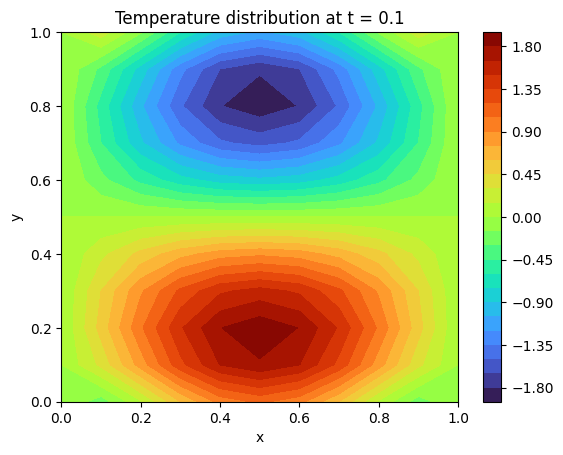

In [7]:
import numpy as np
import matplotlib.pyplot as plt

L = 1
T = 0.1
h = 0.1
k = 0.002
x = np.arange(0,L+h/2,h)[:,None]
y = np.arange(0,L+h/2,h)[None,:]
t = np.arange(0,T+k/2,k)
Nx = x.size
Ny = y.size
Nt = t.size
r = k/h**2
assert r <= 1/4, 'FTCS is unstable'
u = np.zeros((Nx,Ny,Nt))
# Initial condition
u[:,:,0] = 30*np.sin(np.pi*x)*np.cos(np.pi*y)
# Dirichlet boundary conditions
u[0,:,:] = 0
u[-1,:,:] = 0
# FTCS method
i = np.arange(1,Nx-1)[:,None]
m = np.arange(1,Ny-1)[None,:]
for j in range(Nt-1):
    u[i,m,j+1] = (u[i,m,j] + r*(
        u[i-1,m,j] - 2*u[i,m,j] + u[i+1,m,j])
        + r*(
        u[i,m-1,j] - 2*u[i,m,j] + u[i,m+1,j]))

    # Neumann boundary conditions (Centered Difference)
    u[i[:,0],0,j+1] = (u[i[:,0],0,j] + r*(
        u[i[:,0]-1,0,j] - 2*u[i[:,0],0,j] + u[i[:,0]+1,0,j])
        + 2*r*(u[i[:,0],1,j] - u[i[:,0],0,j] - 10*h))

    u[i[:,0],-1,j+1] = (u[i[:,0],-1,j] + r*(
        u[i[:,0]-1,-1,j] - 2*u[i[:,0],-1,j] + u[i[:,0]+1,-1,j])
        + 2*r*(u[i[:,0],-2,j] - u[i[:,0],-1,j] + 10*h))

# Temperature distribution at t = T
plt.figure(facecolor='white')
plt.contourf(x[:,0],y[0,:],u[:,:,-1].T,25,cmap='turbo')
plt.colorbar()
plt.axis('equal')
plt.axis('tight')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Temperature distribution at t = 0.1')
plt.show()

## Άσκηση 8.

Στα εσωτερικά σημεία εφαρμόζουμε τη μέθοδο FTCS:


$$u_{i,m}^{j+1} =u_{i,m}^j +r(u_{i-1,m}^j -2u_{i,m}^j +u_{i+1,m}^j )+r(u_{i,m-1}^j -2u_{i,m}^j +u_{i,m+1}^j )$$

όπου


$$r=\frac{k}{h^2 }$$

**Οριακή συνθήκη Neumann στο κάτω σύνορο (y=0).**


Εφαρμόζουμε Centered Difference:


$$\frac{u_{i,2}^j -u_{i,0}^j }{2h}=10+5x_i (1-x_i )$$

Λύνουμε ως προς το εικονικό σημείο:


$$u_{i,0}^j =u_{i,2}^j -2h[10+5x_i (1-x_i )]$$

Εφαρμόζουμε τη μέθοδο FTCS για m=1:


$$u_{i,1}^{j+1} =u_{i,1}^j +r(u_{i-1,1}^j -2u_{i,1}^j +u_{i+1,1}^j )+r(u_{i,0}^j -2u_{i,1}^j +u_{i,2}^j )$$

Αντικαθιστούμε το εικονικό σημείο:


$$u_{i,1}^{j+1} =u_{i,1}^j +r(u_{i-1,1}^j -2u_{i,1}^j +u_{i+1,1}^j )+r(u_{i,2}^j -2h[10+5x_i (1-x_i )]-2u_{i,1}^j +u_{i,2}^j )$$

Ομαδοποιώντας τους όρους, προκύπτει:


$$u_{i,1}^{j+1} =u_{i,1}^j +r(u_{i-1,1}^j -2u_{i,1}^j +u_{i+1,1}^j )+2r(u_{i,2}^j -u_{i,1}^j -h[10+5x_i (1-x_i )])$$

**Οριακή συνθήκη Neumann στο πάνω σύνορο (y=L).**


Εφαρμόζουμε Centered Difference:


$$\frac{u_{i,N_y +1}^j -u_{i,N_y -1}^j }{2h}=10+5x_i (1-x_i )$$

Λύνουμε ως προς το εικονικό σημείο:


$$u_{i,N_y +1}^j =u_{i,N_y -1}^j +2h[10+5x_i (1-x_i )]$$

Εφαρμόζουμε τη μέθοδο FTCS για m=Ny:


$$u_{i,N_y }^{j+1} =u_{i,N_y }^j +r(u_{i-1,N_y }^j -2u_{i,N_y }^j +u_{i+1,N_y }^j )+r(u_{i,N_y -1}^j -2u_{i,N_y }^j +u_{i,N_y +1}^j )$$

Αντικαθιστούμε το εικονικό σημείο:


$$u_{i,N_y }^{j+1} =u_{i,N_y }^j +r(u_{i-1,N_y }^j -2u_{i,N_y }^j +u_{i+1,N_y }^j )+r(u_{i,N_y -1}^j -2u_{i,N_y }^j +u_{i,N_y -1}^j +2h[10+5x_i (1-x_i )])$$

Ομαδοποιώντας τους όρους, προκύπτει:


$$u_{i,N_y }^{j+1} =u_{i,N_y }^j +r(u_{i-1,N_y }^j -2u_{i,N_y }^j +u_{i+1,N_y }^j )+2r(u_{i,N_y -1}^j -u_{i,N_y }^j +h[10+5x_i (1-x_i )])$$

**Διερεύνηση των γωνιών.**


Από τις οριακές συνθήκες Dirichlet:


$$u_{1,1}^j =20$$

$$u_{1,N_y }^j =30$$

$$u_{N_x ,1}^j =30$$

$$u_{N_x ,N_y }^j =40$$

Η παράγωγος των συνθηκών Dirichlet ως προς y είναι:


$$\frac{\partial (20+10y)}{\partial y}=\frac{\partial (30+10y)}{\partial y}=10$$

Η συνθήκη Neumann για x=0 και x=L=1 δίνει:


$$10+5(0)(1-0)=10$$

$$10+5(1)(1-1)=10$$

Επομένως, οι συνθήκες Dirichlet και Neumann είναι συμβατές στις τέσσερις γωνίες. Οι τιμές των γωνιών καθορίζονται απευθείας από τις συνθήκες Dirichlet.


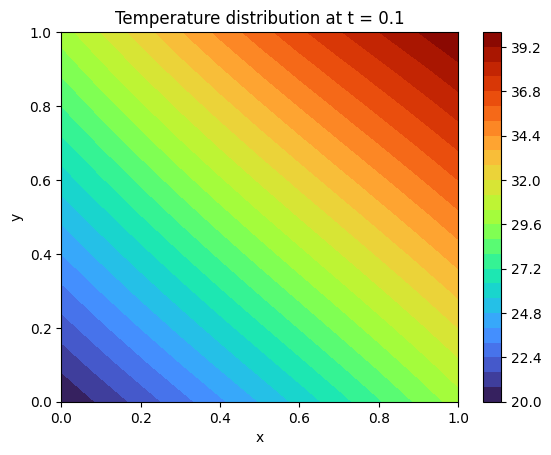

In [8]:
import numpy as np
import matplotlib.pyplot as plt

L = 1
T = 0.1
h = 0.1
k = 0.002

x = np.arange(0,L+h/2,h)[:,None]
y = np.arange(0,L+h/2,h)[None,:]
t = np.arange(0,T+k/2,k)

Nx = x.size
Ny = y.size
Nt = t.size

r = k/h**2

assert r <= 1/4, 'FTCS is unstable'

u = np.zeros((Nx,Ny,Nt))

# Initial condition
u[:,:,0] = ((20 + 10*x + 10*y
    + 5*x*(1-x)*y))

# Dirichlet boundary conditions


u[0,:,:]   = 20 + 10*y.T
u[-1,:,:] = 30 + 10*y.T

# FTCS method
i = np.arange(1,Nx-1)[:,None]
m = np.arange(1,Ny-1)[None,:]

for j in range(Nt-1):

    # Interior points
    u[i,m,j+1] = (u[i,m,j] + r*(
        u[i-1,m,j] - 2*u[i,m,j] + u[i+1,m,j])
        + r*(
        u[i,m-1,j] - 2*u[i,m,j] + u[i,m+1,j]))

    # Neumann boundary at y = 0
    u[i[:,0],0,j+1] = (u[i[:,0],0,j] + r*(
        u[i[:,0]-1,0,j] - 2*u[i[:,0],0,j] + u[i[:,0]+1,0,j])
        + 2*r*(u[i[:,0],1,j] - u[i[:,0],0,j]
        - h*(10 + 5*x[i[:,0],0]*(1-x[i[:,0],0]))))

    # Neumann boundary at y = L
    u[i[:,0],-1,j+1] = (u[i[:,0],-1,j] + r*(
        u[i[:,0]-1,-1,j] - 2*u[i[:,0],-1,j] + u[i[:,0]+1,-1,j])
        + 2*r*(u[i[:,0],-2,j] - u[i[:,0],-1,j]
        + h*(10 + 5*x[i[:,0],0]*(1-x[i[:,0],0]))))


# Temperature distribution at t = T
plt.figure(facecolor='white')
plt.contourf(x[:,0],y[0,:],u[:,:,-1].T,25,cmap='turbo')
plt.colorbar()
plt.axis('equal')
plt.axis('tight')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Temperature distribution at t = 0.1')
plt.show()

## Άσκηση 9.

Στα εσωτερικά σημεία εφαρμόζουμε τη μέθοδο FTCS:


$$u_{i,m}^{j+1} =u_{i,m}^j +r(u_{i-1,m}^j -2u_{i,m}^j +u_{i+1,m}^j )+r(u_{i,m-1}^j -2u_{i,m}^j +u_{i,m+1}^j )$$

$$r=\frac{k}{h^2 }=0.125\le \frac{1}{4}$$

**Αριστερό σύνορο (x=0).**


Εφαρμόζουμε Centered Difference:


$$\frac{u_{2,m}^j -u_{0,m}^j }{2h}=5+y_m$$

Λύνουμε ως προς το εικονικό σημείο:


$$u_{0,m}^j =u_{2,m}^j -2h(5+y_m )$$

Αντικαθιστούμε στη μέθοδο FTCS:


$$u_{1,m}^{j+1} =u_{1,m}^j +2r(u_{2,m}^j -u_{1,m}^j -h(5+y_m ))+r(u_{1,m-1}^j -2u_{1,m}^j +u_{1,m+1}^j )$$

**Δεξί σύνορο (x=L).**


Εφαρμόζουμε Centered Difference:


$$\frac{u_{N_x +1,m}^j -u_{N_x -1,m}^j }{2h}=13+y_m$$

Λύνουμε ως προς το εικονικό σημείο:


$$u_{N_x +1,m}^j =u_{N_x -1,m}^j +2h(13+y_m )$$

Αντικαθιστούμε στη μέθοδο FTCS:


$$u_{N_x ,m}^{j+1} =u_{N_x ,m}^j +2r(u_{N_x -1,m}^j -u_{N_x ,m}^j +h(13+y_m ))+r(u_{N_x ,m-1}^j -2u_{N_x ,m}^j +u_{N_x ,m+1}^j )$$

**Κάτω σύνορο (y=0).**


Εφαρμόζουμε Centered Difference:


$$\frac{u_{i,2}^j -u_{i,0}^j }{2h}=3+x_i$$

Λύνουμε ως προς το εικονικό σημείο:


$$u_{i,0}^j =u_{i,2}^j -2h(3+x_i )$$

Αντικαθιστούμε στη μέθοδο FTCS:


$$u_{i,1}^{j+1} =u_{i,1}^j +r(u_{i-1,1}^j -2u_{i,1}^j +u_{i+1,1}^j )+2r(u_{i,2}^j -u_{i,1}^j -h(3+x_i ))$$

**Πάνω σύνορο (y=L).**


Εφαρμόζουμε Centered Difference:


$$\frac{u_{i,N_y +1}^j -u_{i,N_y -1}^j }{2h}=7+x_i$$

Λύνουμε ως προς το εικονικό σημείο:


$$u_{i,N_y +1}^j =u_{i,N_y -1}^j +2h(7+x_i )$$

Αντικαθιστούμε στη μέθοδο FTCS:


$$u_{i,N_y }^{j+1} =u_{i,N_y }^j +r(u_{i-1,N_y }^j -2u_{i,N_y }^j +u_{i+1,N_y }^j )+2r(u_{i,N_y -1}^j -u_{i,N_y }^j +h(7+x_i ))$$

**Γωνίες.** Αντικαθιστούμε δύο εικονικά σημεία σε κάθε γωνία:


$$u_{1,1}^{j+1} =u_{1,1}^j +2r(u_{2,1}^j -u_{1,1}^j -5h)+2r(u_{1,2}^j -u_{1,1}^j -3h)$$

$$u_{N_x ,1}^{j+1} =u_{N_x ,1}^j +2r(u_{N_x -1,1}^j -u_{N_x ,1}^j +13h)+2r(u_{N_x ,2}^j -u_{N_x ,1}^j -5h)$$

$$u_{1,N_y }^{j+1} =u_{1,N_y }^j +2r(u_{2,N_y }^j -u_{1,N_y }^j -7h)+2r(u_{1,N_y -1}^j -u_{1,N_y }^j +7h)$$

$$u_{N_x ,N_y }^{j+1} =u_{N_x ,N_y }^j +2r(u_{N_x -1,N_y }^j -u_{N_x ,N_y }^j +15h)+2r(u_{N_x ,N_y -1}^j -u_{N_x ,N_y }^j +9h)$$

Η αναλυτική λύση είναι:


$$u(x,y,t)=20+5x+3y+2x^2 +y^2 +xy+6t$$

Επομένως, στο t = 0.3, η θερμοκρασία κυμαίνεται από 21.8 έως 53.8. Η αριθμητική λύση συμπίπτει με την αναλυτική έως την ακρίβεια στρογγυλοποίησης.


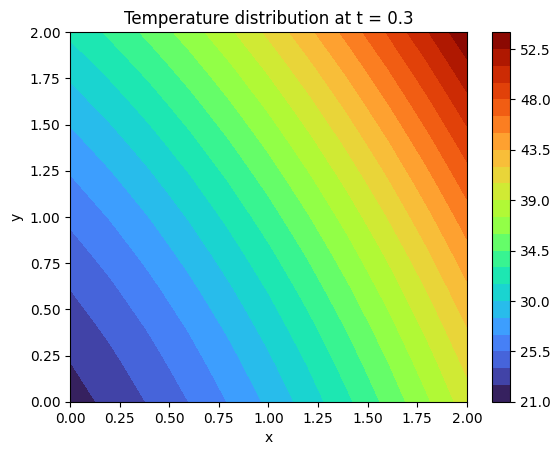

In [9]:
import numpy as np
import matplotlib.pyplot as plt

L = 2
T = 0.3
h = 0.2
k = 0.005

x = np.arange(0,L+h/2,h)[:,None]
y = np.arange(0,L+h/2,h)[None,:]
t = np.arange(0,T+k/2,k)

Nx = x.size
Ny = y.size
Nt = t.size

r = k/h**2
assert r <= 1/4, 'FTCS is unstable'

u = np.zeros((Nx,Ny,Nt))

# Initial condition
u[:,:,0] = 20 + 5*x + 3*y + 2*x**2 + y**2 + x*y

# FTCS method
i = np.arange(1,Nx-1)[:,None]
m = np.arange(1,Ny-1)[None,:]

for j in range(Nt-1):
    # Interior points
    u[i,m,j+1] = (u[i,m,j] + r*(
        u[i-1,m,j] - 2*u[i,m,j] + u[i+1,m,j])
        + r*(u[i,m-1,j] - 2*u[i,m,j] + u[i,m+1,j]))

    # Neumann boundary at x = 0
    u[0,m[0,:],j+1] = (u[0,m[0,:],j] + 2*r*(
        u[1,m[0,:],j] - u[0,m[0,:],j] - h*(5+y[0,m[0,:]]))
        + r*(u[0,m[0,:]-1,j] - 2*u[0,m[0,:],j] + u[0,m[0,:]+1,j]))

    # Neumann boundary at x = L
    u[-1,m[0,:],j+1] = (u[-1,m[0,:],j] + 2*r*(
        u[-2,m[0,:],j] - u[-1,m[0,:],j] + h*(13+y[0,m[0,:]]))
        + r*(u[-1,m[0,:]-1,j] - 2*u[-1,m[0,:],j] + u[-1,m[0,:]+1,j]))

    # Neumann boundary at y = 0
    u[i[:,0],0,j+1] = (u[i[:,0],0,j] + r*(
        u[i[:,0]-1,0,j] - 2*u[i[:,0],0,j] + u[i[:,0]+1,0,j])
        + 2*r*(u[i[:,0],1,j] - u[i[:,0],0,j] - h*(3+x[i[:,0],0])))

    # Neumann boundary at y = L
    u[i[:,0],-1,j+1] = (u[i[:,0],-1,j] + r*(
        u[i[:,0]-1,-1,j] - 2*u[i[:,0],-1,j] + u[i[:,0]+1,-1,j])
        + 2*r*(u[i[:,0],-2,j] - u[i[:,0],-1,j] + h*(7+x[i[:,0],0])))

    # Corners
    u[0,0,j+1] = (u[0,0,j]
        + 2*r*(u[1,0,j] - u[0,0,j] - 5*h)
        + 2*r*(u[0,1,j] - u[0,0,j] - 3*h))

    u[-1,0,j+1] = (u[-1,0,j]
        + 2*r*(u[-2,0,j] - u[-1,0,j] + 13*h)
        + 2*r*(u[-1,1,j] - u[-1,0,j] - 5*h))

    u[0,-1,j+1] = (u[0,-1,j]
        + 2*r*(u[1,-1,j] - u[0,-1,j] - 7*h)
        + 2*r*(u[0,-2,j] - u[0,-1,j] + 7*h))

    u[-1,-1,j+1] = (u[-1,-1,j]
        + 2*r*(u[-2,-1,j] - u[-1,-1,j] + 15*h)
        + 2*r*(u[-1,-2,j] - u[-1,-1,j] + 9*h))

# Temperature distribution at t = T
plt.figure(facecolor='white')
plt.contourf(x[:,0],y[0,:],u[:,:,-1].T,25,cmap='turbo')
plt.colorbar()
plt.axis('equal')
plt.axis('tight')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Temperature distribution at t = 0.3')
plt.show()

In [10]:
# Verification
u_exact = 20 + 5*x + 3*y + 2*x**2 + y**2 + x*y + 6*T
print(f'Maximum absolute error = {np.max(np.abs(u[:,:,-1]-u_exact)):.3e}')

Maximum absolute error = 1.492e-13




## Άσκηση 10.

Στα εσωτερικά σημεία εφαρμόζουμε τη μέθοδο FTCS:


$$u_{i,m}^{j+1} =u_{i,m}^j +r(u_{i-1,m}^j -2u_{i,m}^j +u_{i+1,m}^j )+r(u_{i,m-1}^j -2u_{i,m}^j +u_{i,m+1}^j )$$

$$r=\frac{k}{h^2 }=0.125\le \frac{1}{4}$$

**Αριστερό σύνορο (x=0): Forward Difference.**


$$\frac{u_{2,m}^j -u_{1,m}^j }{h}=5+y_m$$

$$u_{1,m}^j =u_{2,m}^j -h(5+y_m )$$

**Δεξί σύνορο (x=L): Backward Difference.**


$$\frac{u_{N_x ,m}^j -u_{N_x -1,m}^j }{h}=13+y_m$$

$$u_{N_x ,m}^j =u_{N_x -1,m}^j +h(13+y_m )$$

**Κάτω σύνορο (y=0): Forward Difference.**


$$\frac{u_{i,2}^j -u_{i,1}^j }{h}=3+x_i$$

$$u_{i,1}^j =u_{i,2}^j -h(3+x_i )$$

**Πάνω σύνορο (y=L): Backward Difference.**


$$\frac{u_{i,N_y }^j -u_{i,N_y -1}^j }{h}=7+x_i$$

$$u_{i,N_y }^j =u_{i,N_y -1}^j +h(7+x_i )$$

**Γωνίες.** Εφαρμόζουμε πρώτα τις συνθήκες κατά x στα εσωτερικά σημεία των πλευρών και στη συνέχεια τις συνθήκες κατά y σε ολόκληρη την κάτω και πάνω πλευρά. Έτσι ικανοποιούνται και οι δύο διακριτές συνθήκες στις γωνίες, λόγω της συμβατότητας των δεδομένων.


Η αρχική συνθήκη είναι συμβατή με τις συνεχείς συνθήκες Neumann, αλλά όχι ακριβώς με τις μονόπλευρες διαφορές πρώτης τάξης. Επιβάλλουμε τις διακριτές συνθήκες πριν από κάθε βήμα FTCS, καθώς και στο τελικό χρονικό επίπεδο.


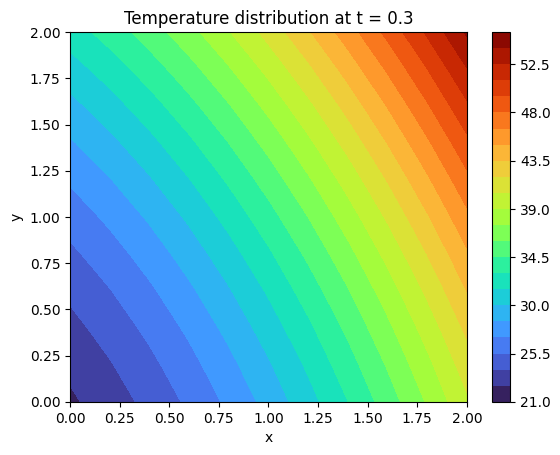

In [11]:
import numpy as np
import matplotlib.pyplot as plt

L = 2
T = 0.3
h = 0.2
k = 0.005

x = np.arange(0,L+h/2,h)[:,None]
y = np.arange(0,L+h/2,h)[None,:]
t = np.arange(0,T+k/2,k)

Nx = x.size
Ny = y.size
Nt = t.size

r = k/h**2
assert r <= 1/4, 'FTCS is unstable'

u = np.zeros((Nx,Ny,Nt))

# Initial condition
u[:,:,0] = 20 + 5*x + 3*y + 2*x**2 + y**2 + x*y

i = np.arange(1,Nx-1)[:,None]
m = np.arange(1,Ny-1)[None,:]

# Neumann boundary conditions at t = 0
u[0,m[0,:],0]   = u[1,m[0,:],0] - h*(5+y[0,m[0,:]])
u[-1,m[0,:],0] = u[-2,m[0,:],0] + h*(13+y[0,m[0,:]])
u[:,0,0]   = u[:,1,0] - h*(3+x[:,0])
u[:,-1,0] = u[:,-2,0] + h*(7+x[:,0])

# FTCS method
for j in range(Nt-1):
    u[i,m,j+1] = (u[i,m,j] + r*(
        u[i-1,m,j] - 2*u[i,m,j] + u[i+1,m,j])
        + r*(
        u[i,m-1,j] - 2*u[i,m,j] + u[i,m+1,j]))

    # Neumann boundary conditions (Forward and Backward Difference)
    u[0,m[0,:],j+1]   = u[1,m[0,:],j+1] - h*(5+y[0,m[0,:]])
    u[-1,m[0,:],j+1] = u[-2,m[0,:],j+1] + h*(13+y[0,m[0,:]])
    u[:,0,j+1]   = u[:,1,j+1] - h*(3+x[:,0])
    u[:,-1,j+1] = u[:,-2,j+1] + h*(7+x[:,0])

# Temperature distribution at t = T
plt.figure(facecolor='white')
plt.contourf(x[:,0],y[0,:],u[:,:,-1].T,25,cmap='turbo')
plt.colorbar()
plt.axis('equal')
plt.axis('tight')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Temperature distribution at t = 0.3')
plt.show()

In [12]:
# Verification
u_exact = 20 + 5*x + 3*y + 2*x**2 + y**2 + x*y + 6*T
print(f'Maximum absolute error = {np.max(np.abs(u[:,:,-1]-u_exact)):.3e}')

Maximum absolute error = 4.417e-01
